Authors:
- Becker Awqatty
- Ben... (I forgot T-T sorry)

# setup

In [1]:
%pip install -qU kaggle

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
import os
import subprocess
import zipfile
from google.colab import userdata

kaggle_api_token = userdata.get("KAGGLE_API_TOKEN")
os.environ["KAGGLE_API_TOKEN"] = kaggle_api_token

COMPETITION_NAME = "cu-boulder-stat-learning-fall-2026-final-project"
COMPETITION_URL = f"https://www.kaggle.com/competitions/{COMPETITION_NAME}"

try:
  df_train = pd.read_csv("/content/data/train.csv", index_col="ID")
  df_test = pd.read_csv("/content/data/test.csv", index_col="ID")
except:
  print("data not found. downloading...")
  r = subprocess.run(["kaggle", "competitions", "download", "-c", COMPETITION_NAME, "-p", "data"], capture_output=True, text=True)
  assert r.returncode == 0, "❌ download failed"
  print("download complete. unzipping files...")
  with zipfile.ZipFile("/content/data/cu-boulder-stat-learning-fall-2026-final-project.zip") as zf:
    zf.extractall("/content/data")
  print("unzip complete.")

  df_train = pd.read_csv("/content/data/train.csv", index_col="ID")
  df_test = pd.read_csv("/content/data/test.csv", index_col="ID")
finally:
  print("✅ data loaded!")


✅ data loaded!


# data formatting

In [27]:
cols_categorical = "x4 x5 x10 Y".split()

for col in cols_categorical:
  df_train[col] = df_train[col].astype('category')

# summary stats

In [28]:
display(df_train.describe())
display(df_train.head())

for col in cols_categorical:
  display(df_train[col].value_counts())

,x1,x2,x3,x6,x7,x8,x9
count,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000,15000.000000
mean,0.021978,0.001201,-0.009654,-0.011412,-0.003977,0.006012,0.024428
std,0.998435,0.996935,1.393548,0.992299,1.003482,1.001646,0.994844
min,-3.653700,-3.669900,-1.993900,-4.111100,-4.335100,-4.624100,-3.949600
25%,-0.653500,-0.682850,-1.030025,-0.683650,-0.689400,-0.669125,-0.647625
50%,0.022500,0.002500,-0.323250,-0.014400,-0.013850,-0.000850,0.028550
75%,0.698425,0.664825,0.671400,0.668150,0.664850,0.683225,0.705450
max,3.792700,4.359300,8.918300,3.741100,3.849900,3.903700,4.235000


,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,Y
ID,,,,,,,,,,,
1,0.0173,-1.0968,0.3725,0,2,0.0547,1.5471,-0.3371,-0.4551,1,0
2,-0.2145,0.5228,0.2572,0,0,0.0489,-1.9378,0.2004,-0.7517,2,0
3,-1.4413,0.1400,-0.1907,1,0,-2.2845,-0.0585,-0.0021,-0.5917,0,1
4,-0.5113,-0.5586,-0.4460,1,0,1.4341,0.7005,-2.6717,-0.7258,0,0
5,-0.8045,-0.7673,-1.2111,0,0,0.2241,-0.2277,-1.7400,-0.2095,3,0


,count
x4,
0,7533
1,7467


,count
x5,
0,6019
1,5187
2,3794


,count
x10,
3,3891
2,3737
0,3712
1,3660


,count
Y,
0,10827
1,4173


# categorical interactions

In [29]:
for col in cols_categorical[:-1]:
  display(df_train.loc[df_train["Y"] == 1, col].value_counts() / df_train[col].value_counts())

,count
x4,
0,0.283287
1,0.273068


,count
x5,
0,0.263997
1,0.266628
2,0.316552


,count
x10,
3,0.282447
2,0.282580
0,0.274784
1,0.272678


- `x5:2` seems to be correlated with a higher response rate, where `x5:0, x5:1` seem to correlate with a lower response rate
- `x4` and `x10` seem to have little interaction with `Y`

In [31]:
display(df_train.loc[df_train["Y"] == 1, cols_categorical[:-1]].value_counts() / df_train[cols_categorical[:-1]].value_counts())
# display(df_train[cols_categorical].value_counts())
display(min(df_train[cols_categorical[:-1]].value_counts()))

x4  x5  x10
0   0   0      0.278296
        1      0.251701
        2      0.277500
        3      0.274900
    1   0      0.250804
        1      0.271812
        2      0.273952
        3      0.275714
    2   0      0.321199
        1      0.325000
        2      0.351695
        3      0.296524
1   0   0      0.252591
        1      0.248921
        2      0.247682
        3      0.278364
    1   0      0.265432
        1      0.276065
        2      0.261667
        3      0.255952
    2   0      0.305310
        1      0.283298
        2      0.319005
        3      0.329480
Name: count, dtype: float64

442

-> from the table:
- `x4, x5, x10` move the average `Y` rate from ~0.24 to ~0.35
- `Y`'s rate is notably highest at 0.352 for `x4=0, x5=2, x10=2`
- `Y`'s rate is notably lowest at 0.248 for `x4=1, x5=0, x10=2`
- there are some $3+$-variable interactions among the categorical variables `x4, x5, x10, Y`; i.e., the table is more than just an outer product of the marginal probabilities
  - $Y \mid X_i$ can be considered a Bernoulli variable, with dependence on the predictors $X_i$
  - -> the variance of a Bernoulli is $\sigma^2 := p (1 - p)$, where $p$ is the average
  - each set of predictor value combinations has at least 442 samples (see printed value above)
  - -> the variance of the average of these values would be $\frac{\sigma^2}{n} < \frac{\sigma^2}{442} < \frac{(1/4)}{442} \approx 5.656 \times 10^{-4}$
  - a 95% CI generally considers values within $\sim \pm 1.96 \sigma^2 \approx 0.00111$ of the sample mean
  - => any two sample means above that are more than $\sim 0.00222$ apart are likely statistically significantly different
  - there are *many* such values that differ by orders of magnitude more than this threshold

# correlation table

In [8]:
display(df_train.corr())

,x1,x2,x3,x4,x5,x6,x7,x8,x9,x10,Y
x1,1.000000,-0.002112,0.013585,0.010960,0.011986,0.007232,0.001358,0.001182,0.747520,-0.018448,0.246085
x2,-0.002112,1.000000,0.006328,0.008433,-0.002469,-0.003955,0.013893,0.002863,0.003767,-0.013032,0.059530
x3,0.013585,0.006328,1.000000,-0.003247,-0.003091,-0.004821,-0.000597,-0.002756,0.015741,-0.006099,-0.038720
x4,0.010960,0.008433,-0.003247,1.000000,0.002281,0.013578,-0.007025,0.007032,0.003307,-0.007512,-0.011402
x5,0.011986,-0.002469,-0.003091,0.002281,1.000000,-0.005839,-0.011329,0.006237,0.006422,0.008582,0.043221
x6,0.007232,-0.003955,-0.004821,0.013578,-0.005839,1.000000,-0.005730,-0.005175,0.003250,0.013138,0.033396
x7,0.001358,0.013893,-0.000597,-0.007025,-0.011329,-0.005730,1.000000,0.004402,0.004848,-0.002400,0.069439
x8,0.001182,0.002863,-0.002756,0.007032,0.006237,-0.005175,0.004402,1.000000,0.011341,-0.002597,-0.000816
x9,0.747520,0.003767,0.015741,0.003307,0.006422,0.003250,0.004848,0.011341,1.000000,-0.016713,0.184294
x10,-0.018448,-0.013032,-0.006099,-0.007512,0.008582,0.013138,-0.002400,-0.002597,-0.016713,1.000000,0.008219


-> from the table:

- `x1`, `x9` are highly correlated - 0.747
- `Y` is most highly correlated with `x1`, followed by `x9`

# plots - response vs. single predictor

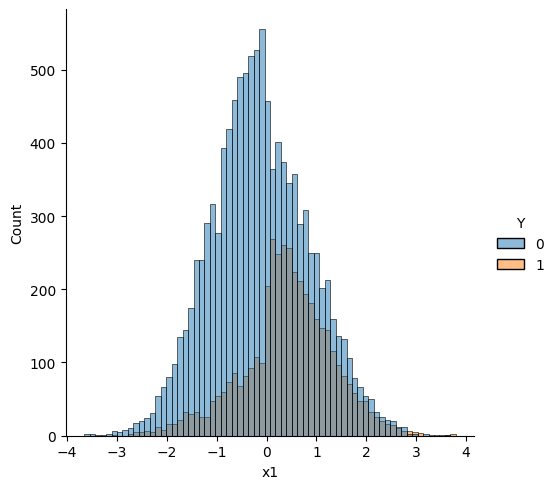

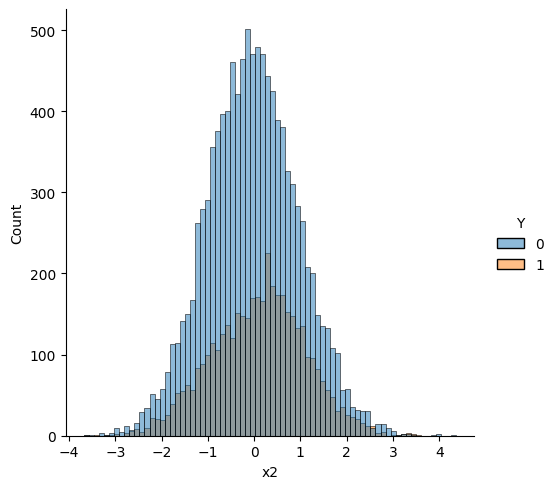

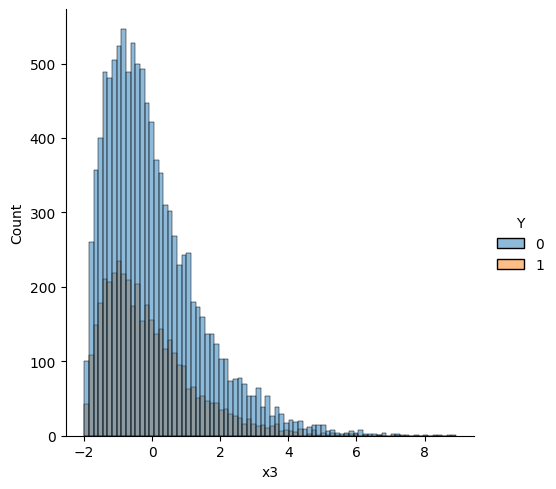

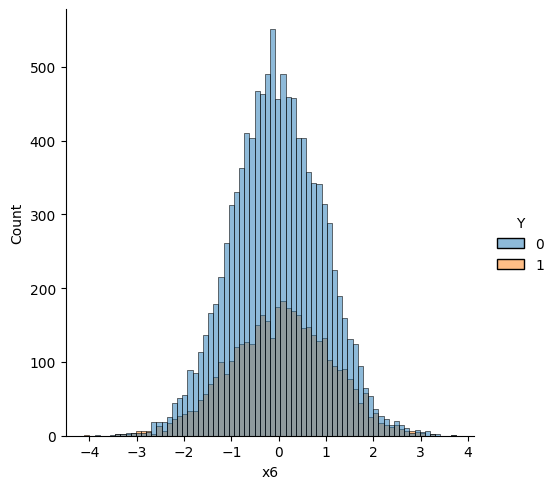

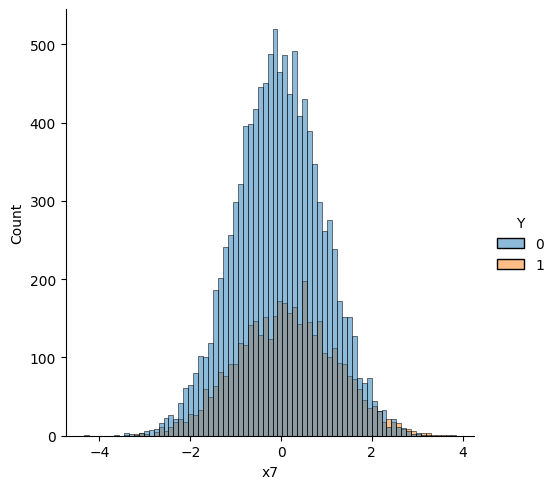

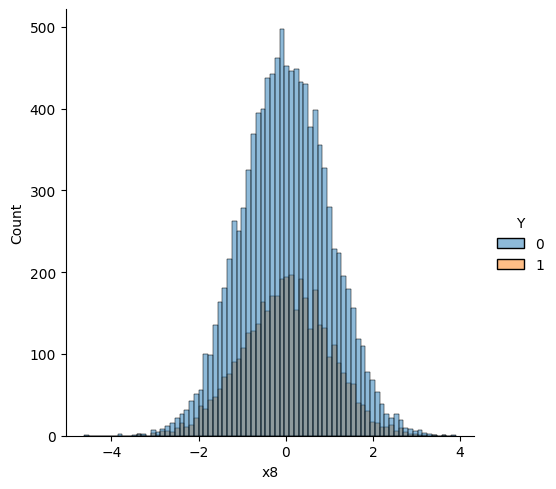

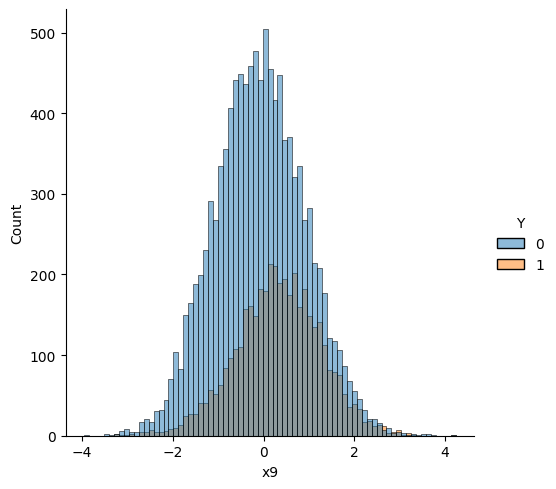

In [9]:
for col in df_train.columns:
  if col in cols_categorical:
    continue
  display(sns.displot(df_train, x=col, hue="Y"))

- `x1` has a notable imbalance to it; specifically, it bears the general normal-distribution shape, but has a piecewise-looking divide about $x_1 = 0$
- `x3` has a skewed shape to it, almost like a [Gamma distribution](https://en.wikipedia.org/wiki/Gamma_distribution)
- `x2` and `x9` have some asymmetry about zero

# $X_1$ as a binary classifier

TODO take `x1`, then:
- take some portion of the points where $x_1 > 0, Y = 1$ and set $Y = 0$
- then do the same for $x_1 < 0, Y = 0$, setting $Y = 1$

-> check: do we get effectively a normal distribution for both $Y$ values?

In [17]:
df_train["x11"] = (df_train.x1 > 0).astype("category")
cols_categorical.insert(-2, "x11")

display(df_train.loc[df_train["Y"] == 1, "x11"].value_counts() / df_train["x11"].value_counts())

,count
x11,
True,0.409699
False,0.142062


-> discretizing `x11` produces a result much stronger than any of the other categorical predictors, with a prediction range of $[0.14, 0.41]$.

# ❌ transform $X_3$

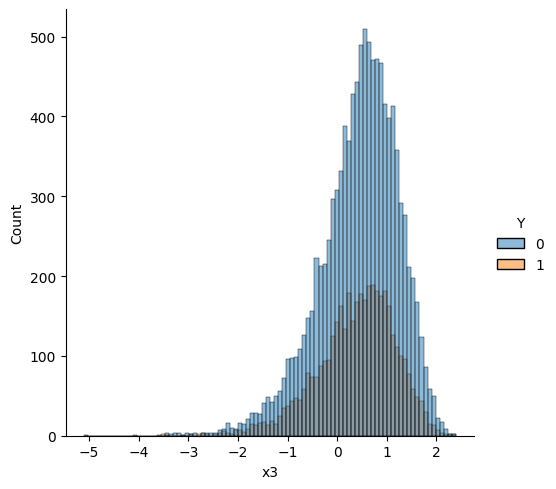

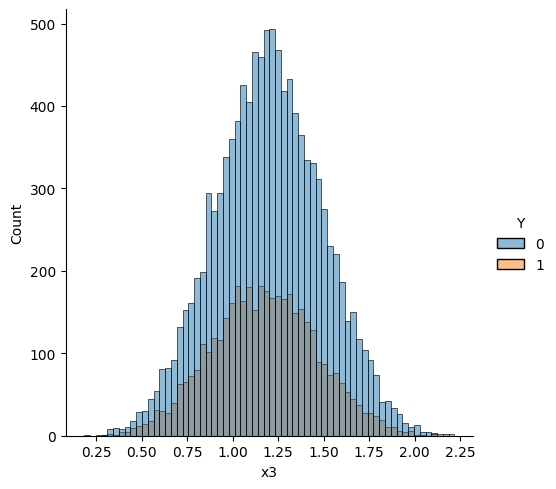

In [10]:
display(sns.displot(x=np.log(df_train.x3 + 2), hue=df_train.Y))
display(sns.displot(x=np.cbrt(df_train.x3 + 2), hue=df_train.Y))

we can try to "even out" `x3`, but it still doesn't quite look right

# predictor interactions via pairwise plots

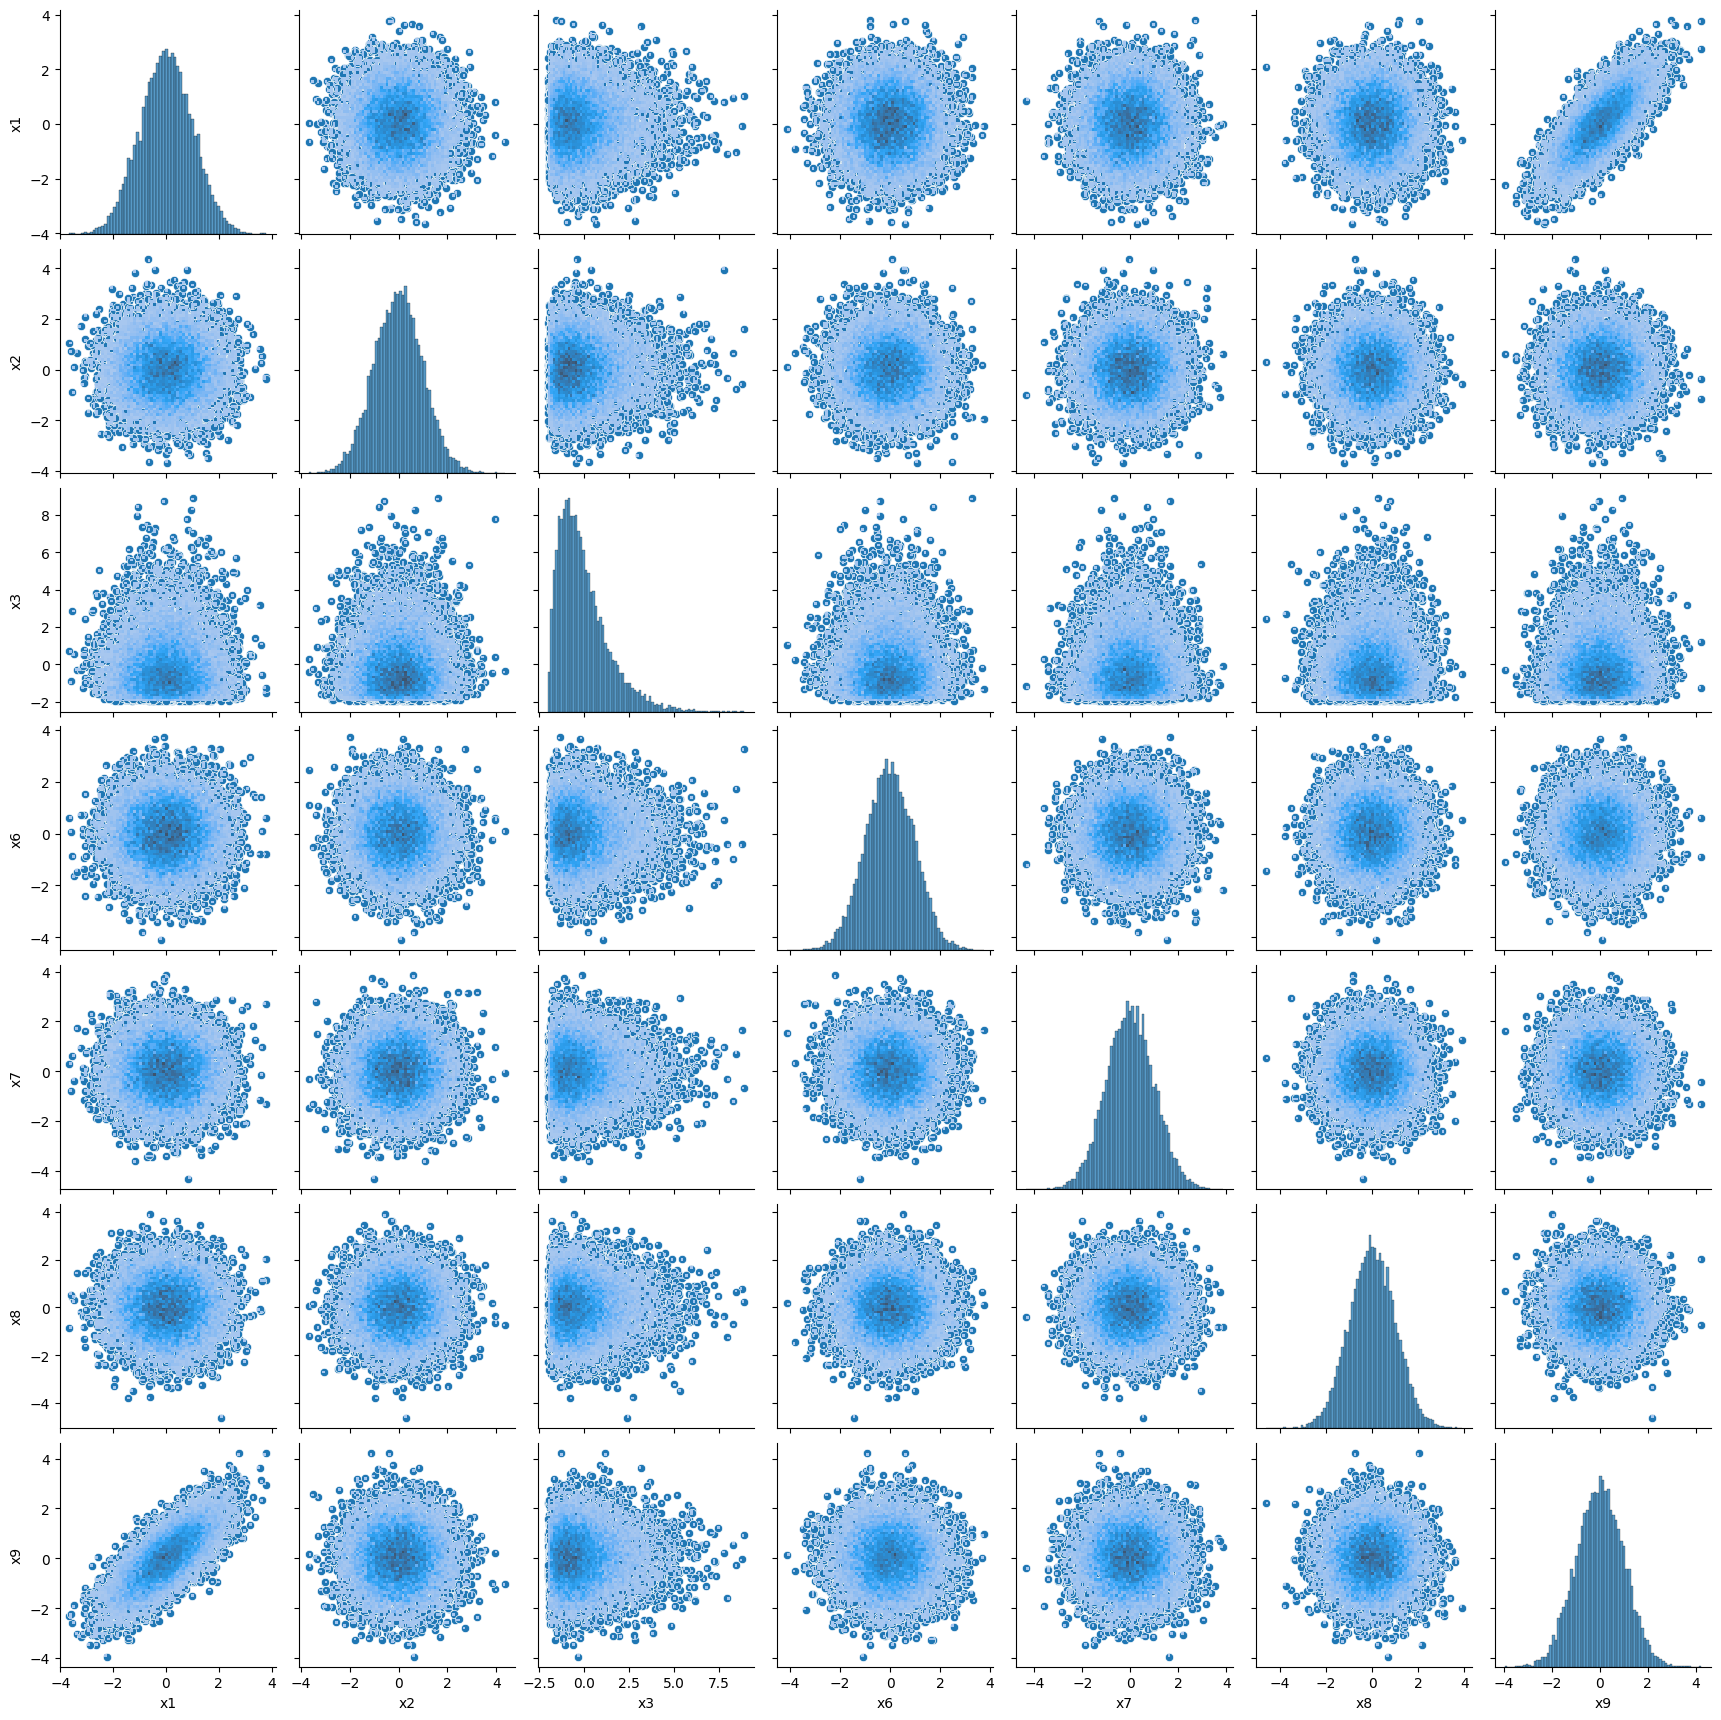

In [16]:
g = sns.pairplot(df_train)
g.map_offdiag(sns.histplot)
# g.map_lower(sns.kdeplot, fill=True)
display(g)

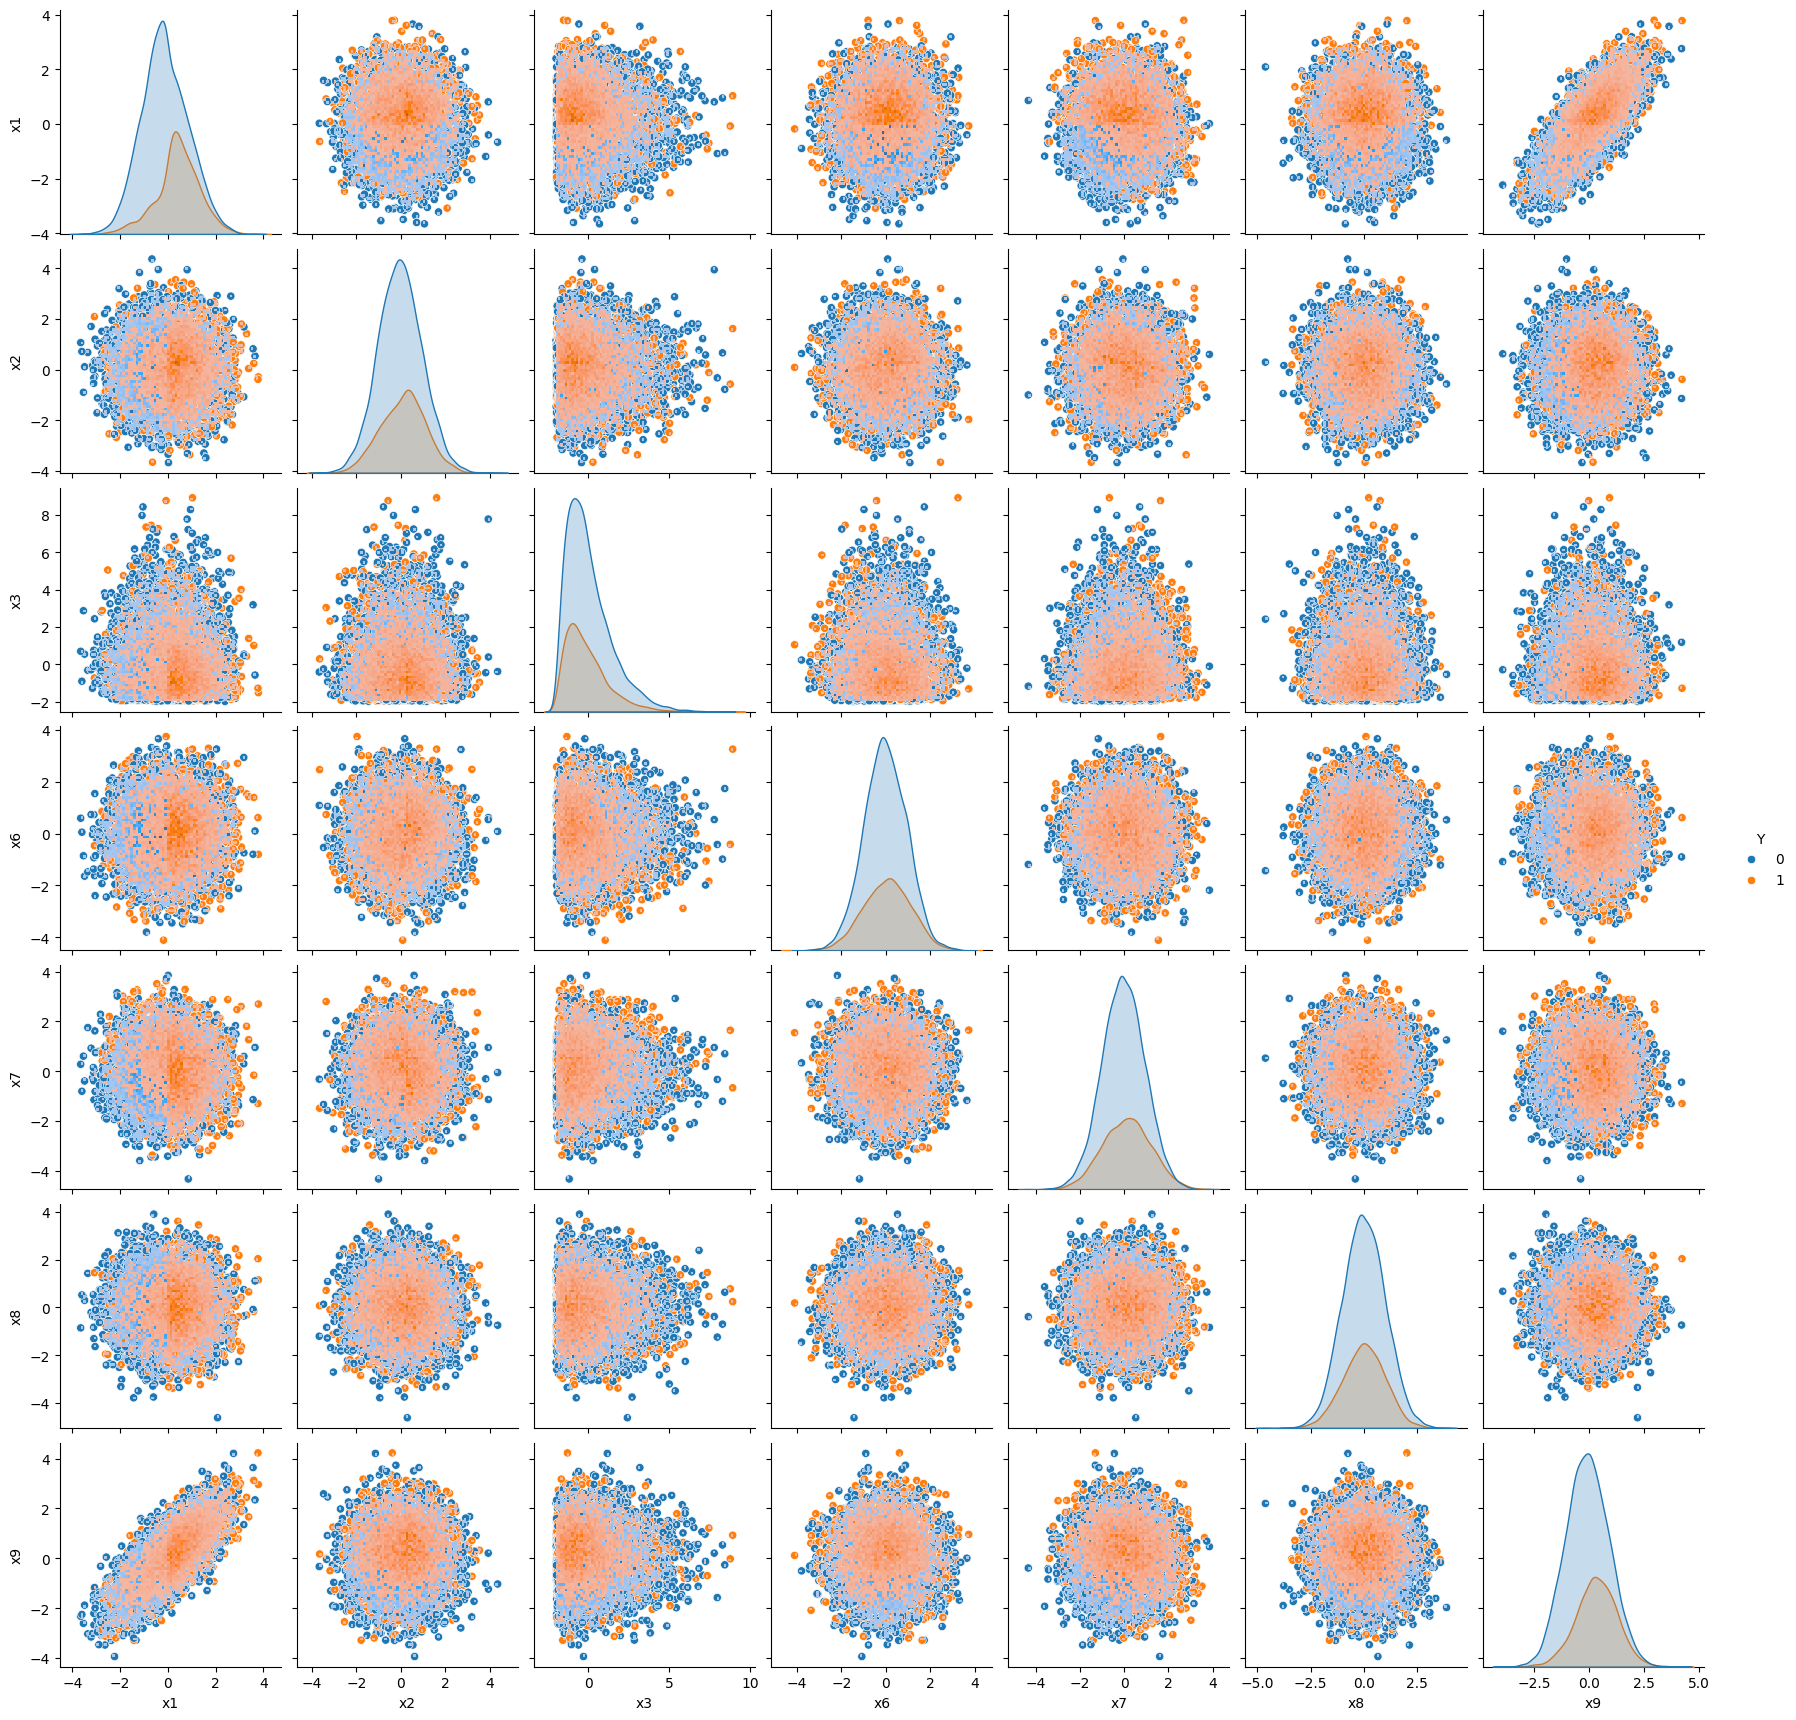

In [18]:
g = sns.pairplot(df_train, hue="Y")
g.map_offdiag(sns.histplot)
# g.map_lower(sns.kdeplot, fill=True)
display(g)

## categorical predictors are independent from numerical predictors

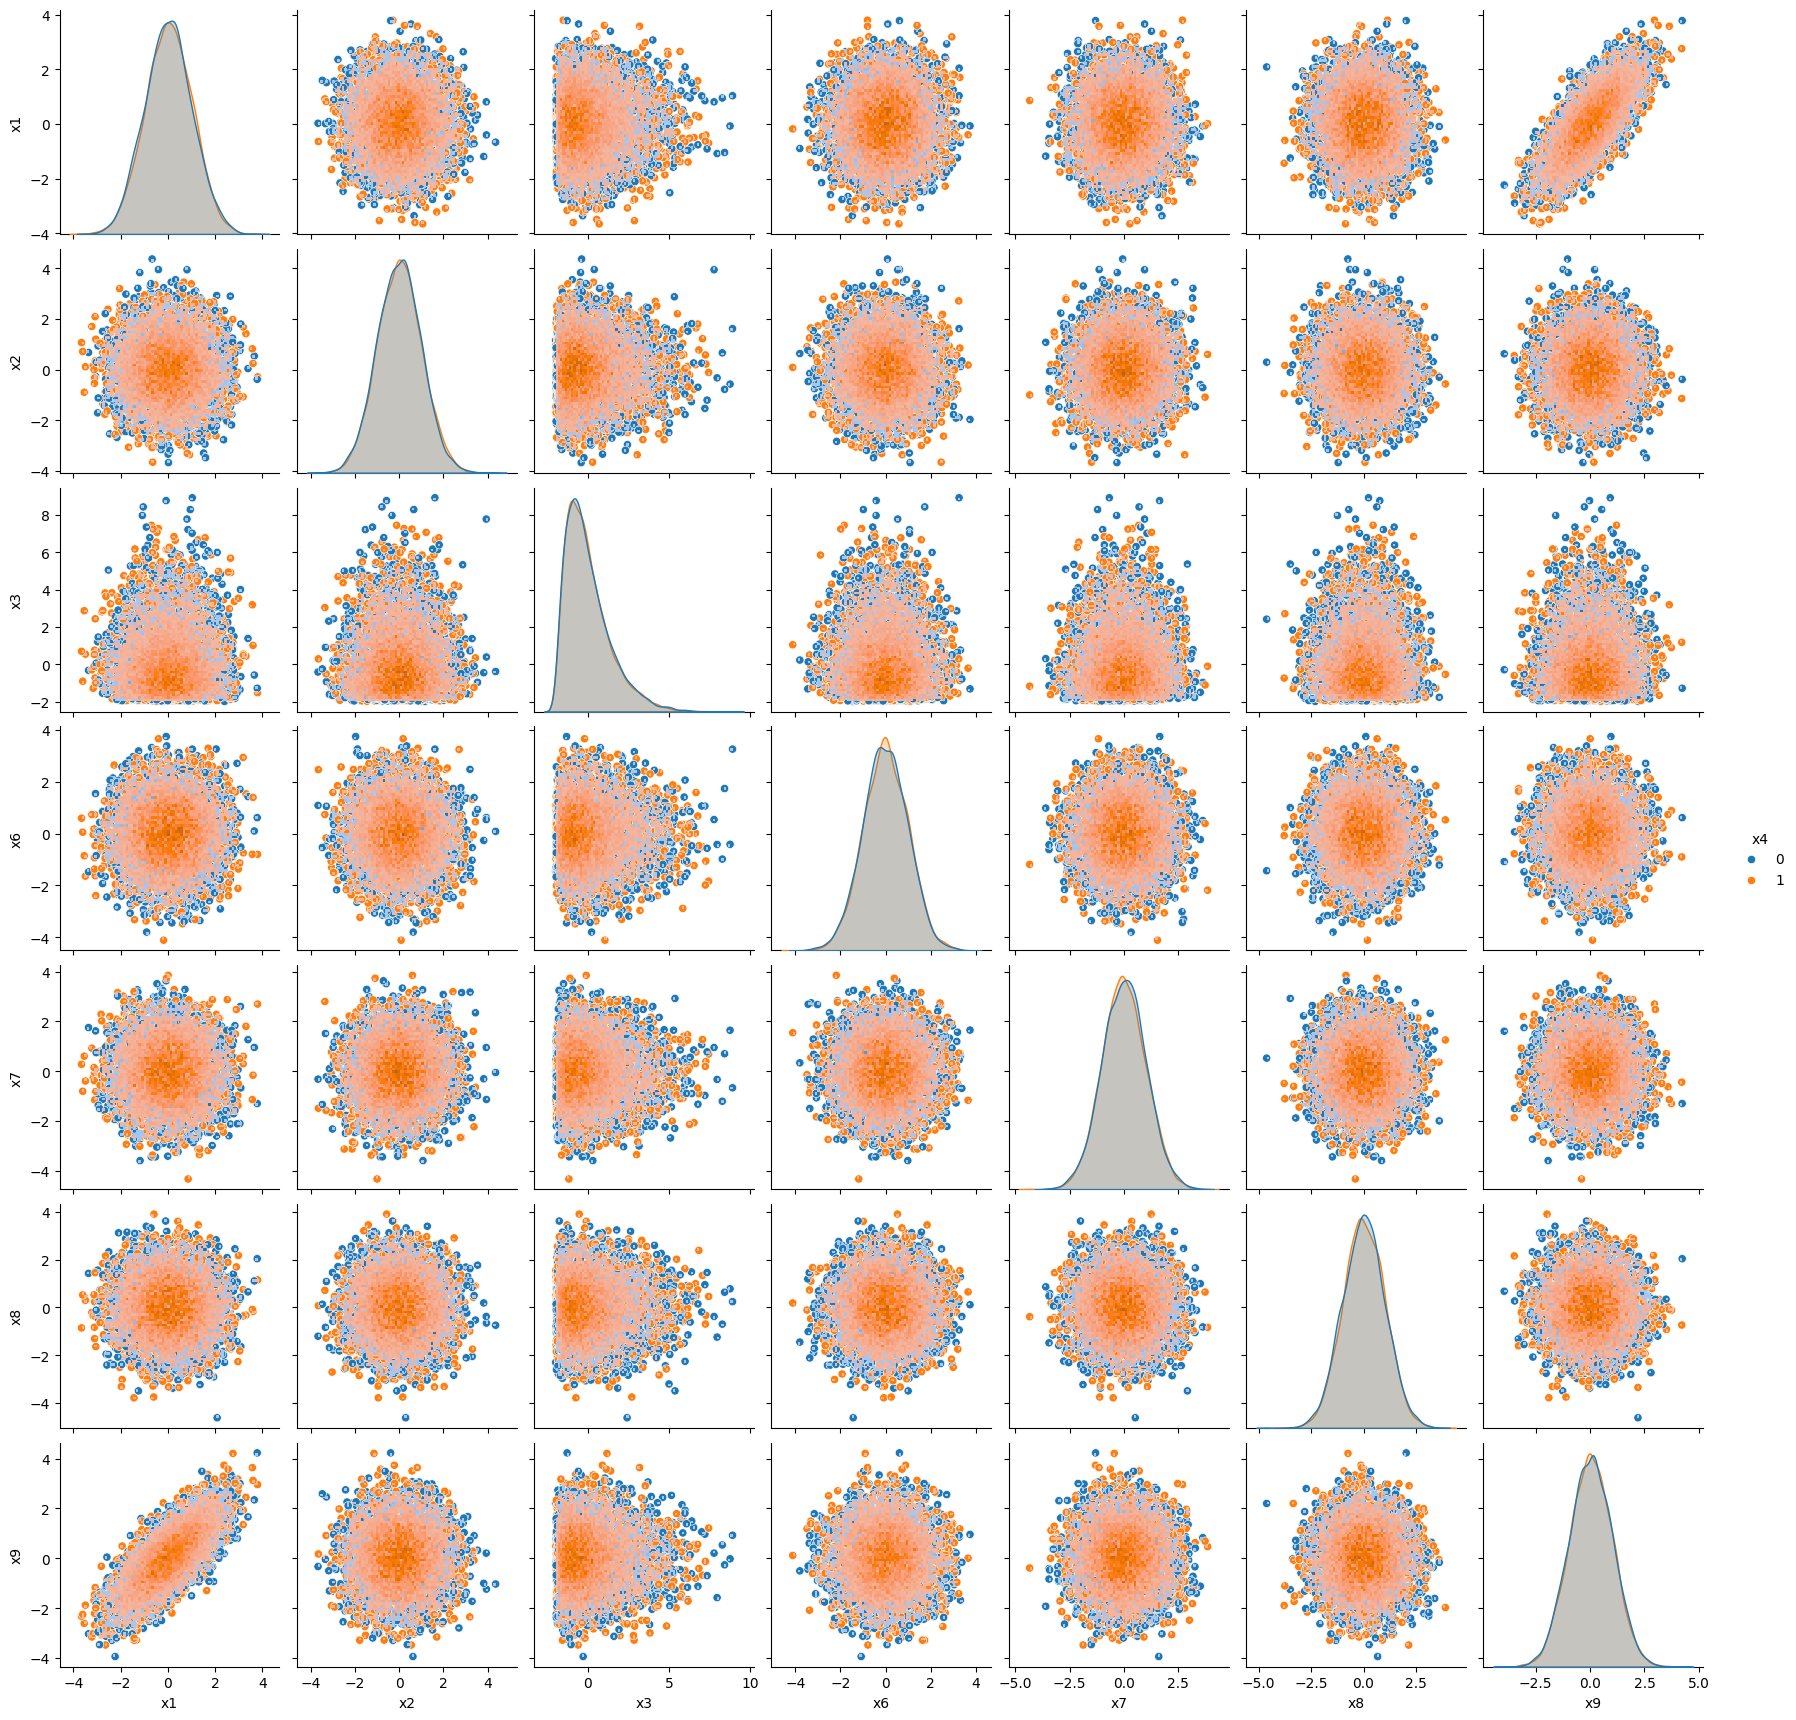

In [19]:
g = sns.pairplot(df_train, hue="x4")
g.map_offdiag(sns.histplot)
# g.map_lower(sns.kdeplot, fill=True)
display(g)

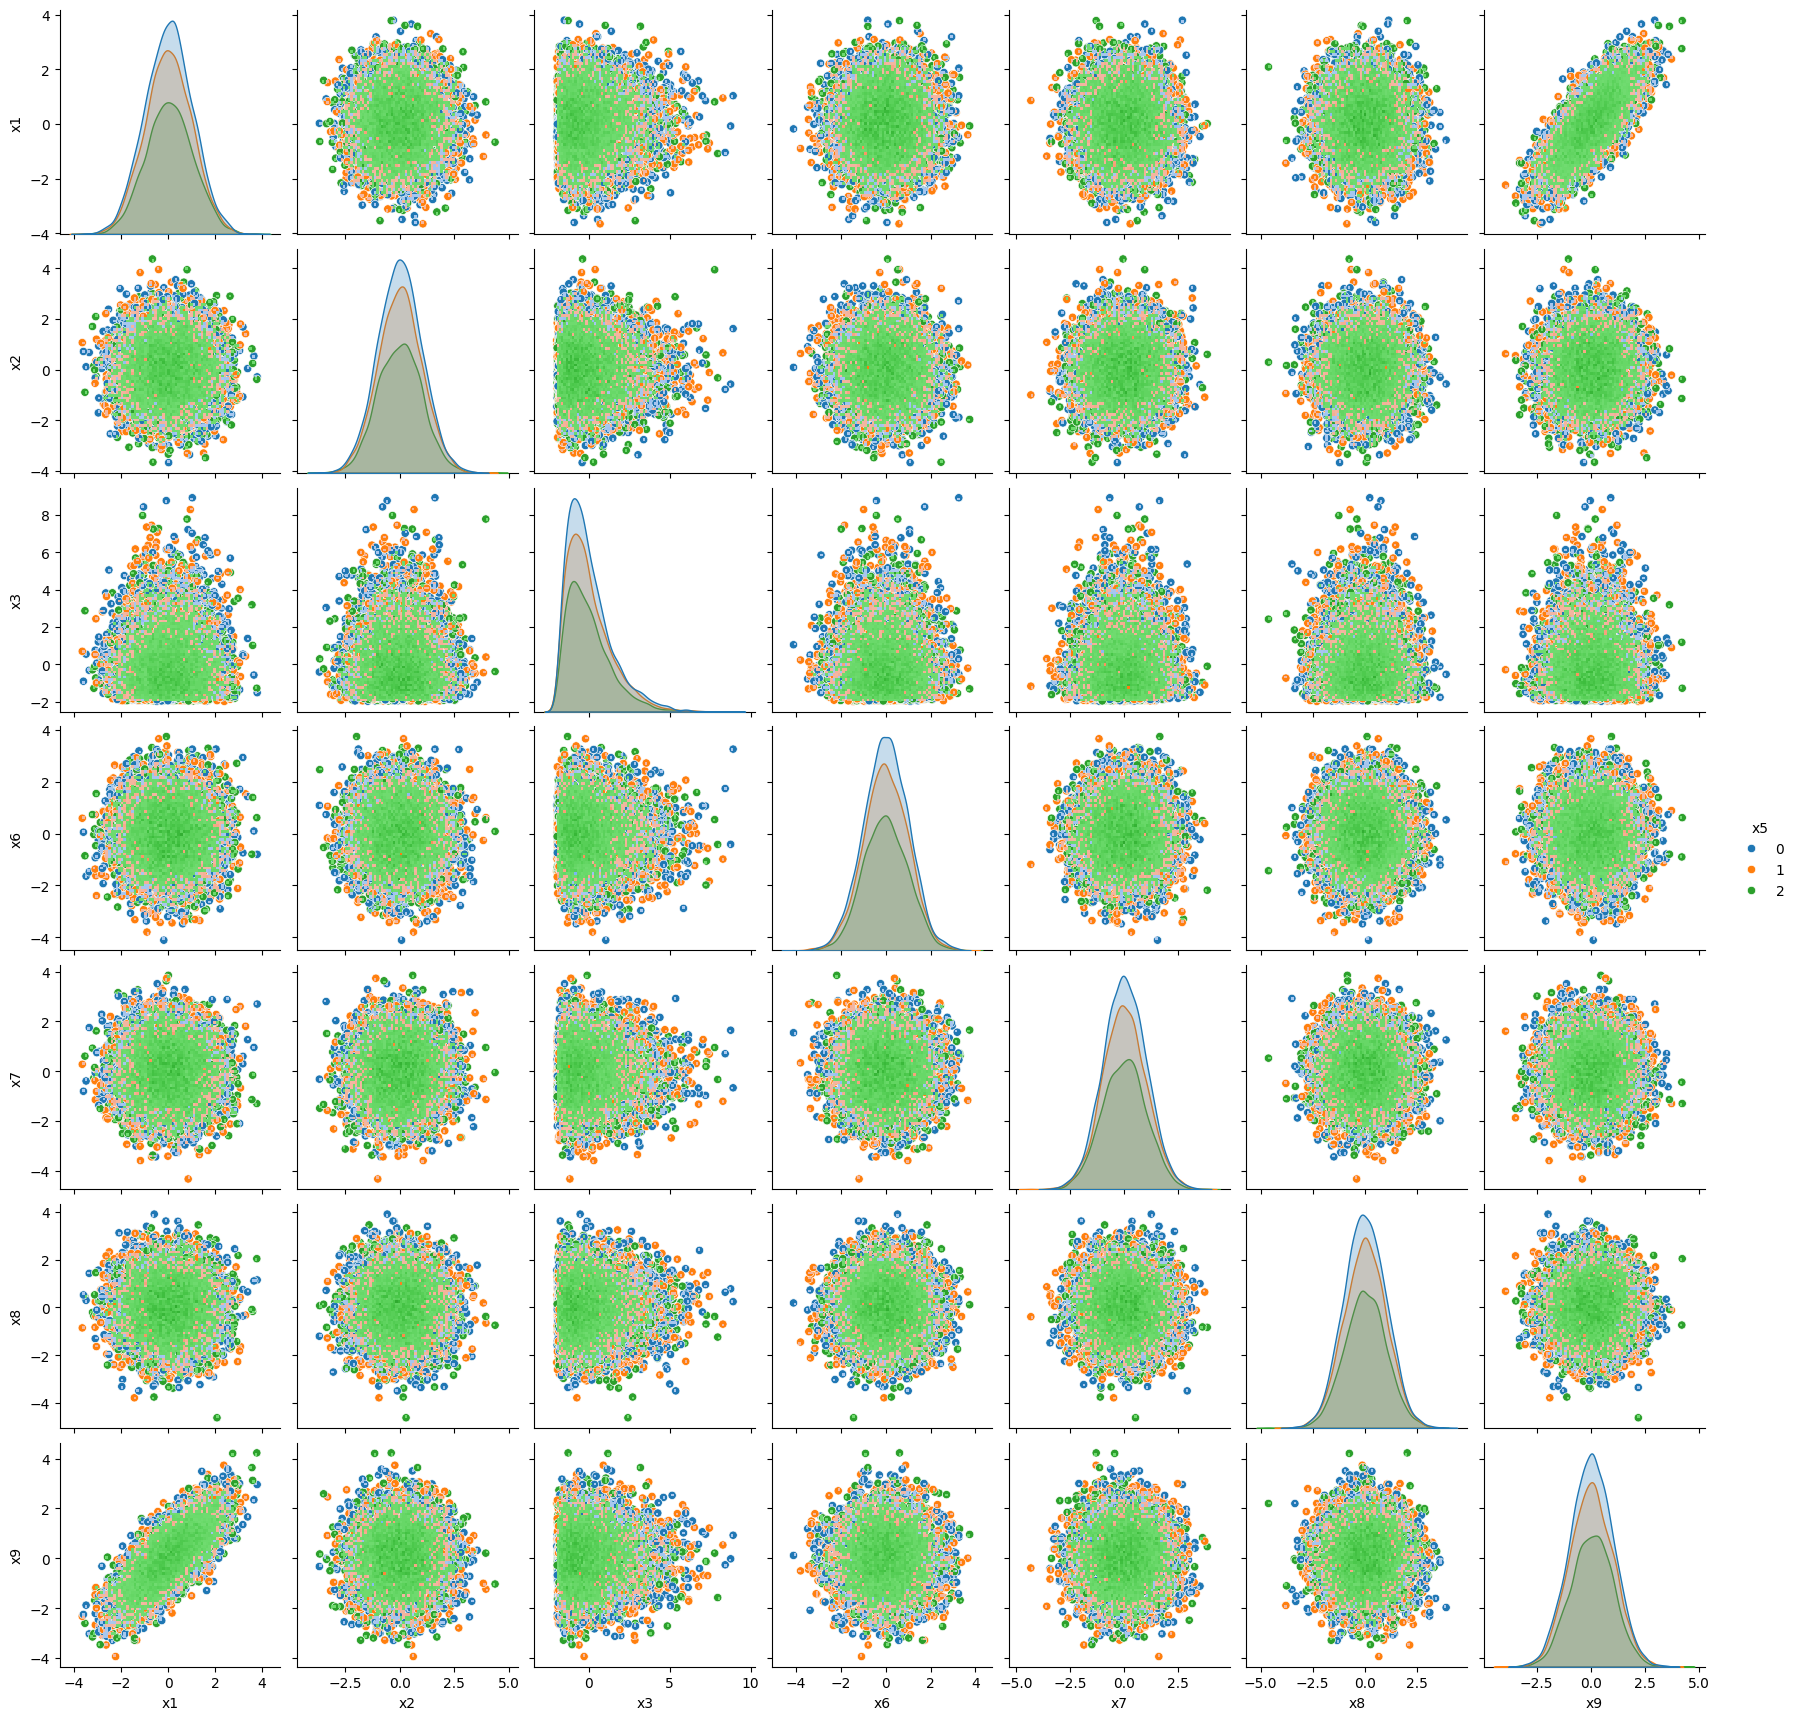

In [20]:
g = sns.pairplot(df_train, hue="x5")
g.map_offdiag(sns.histplot)
# g.map_lower(sns.kdeplot, fill=True)
display(g)

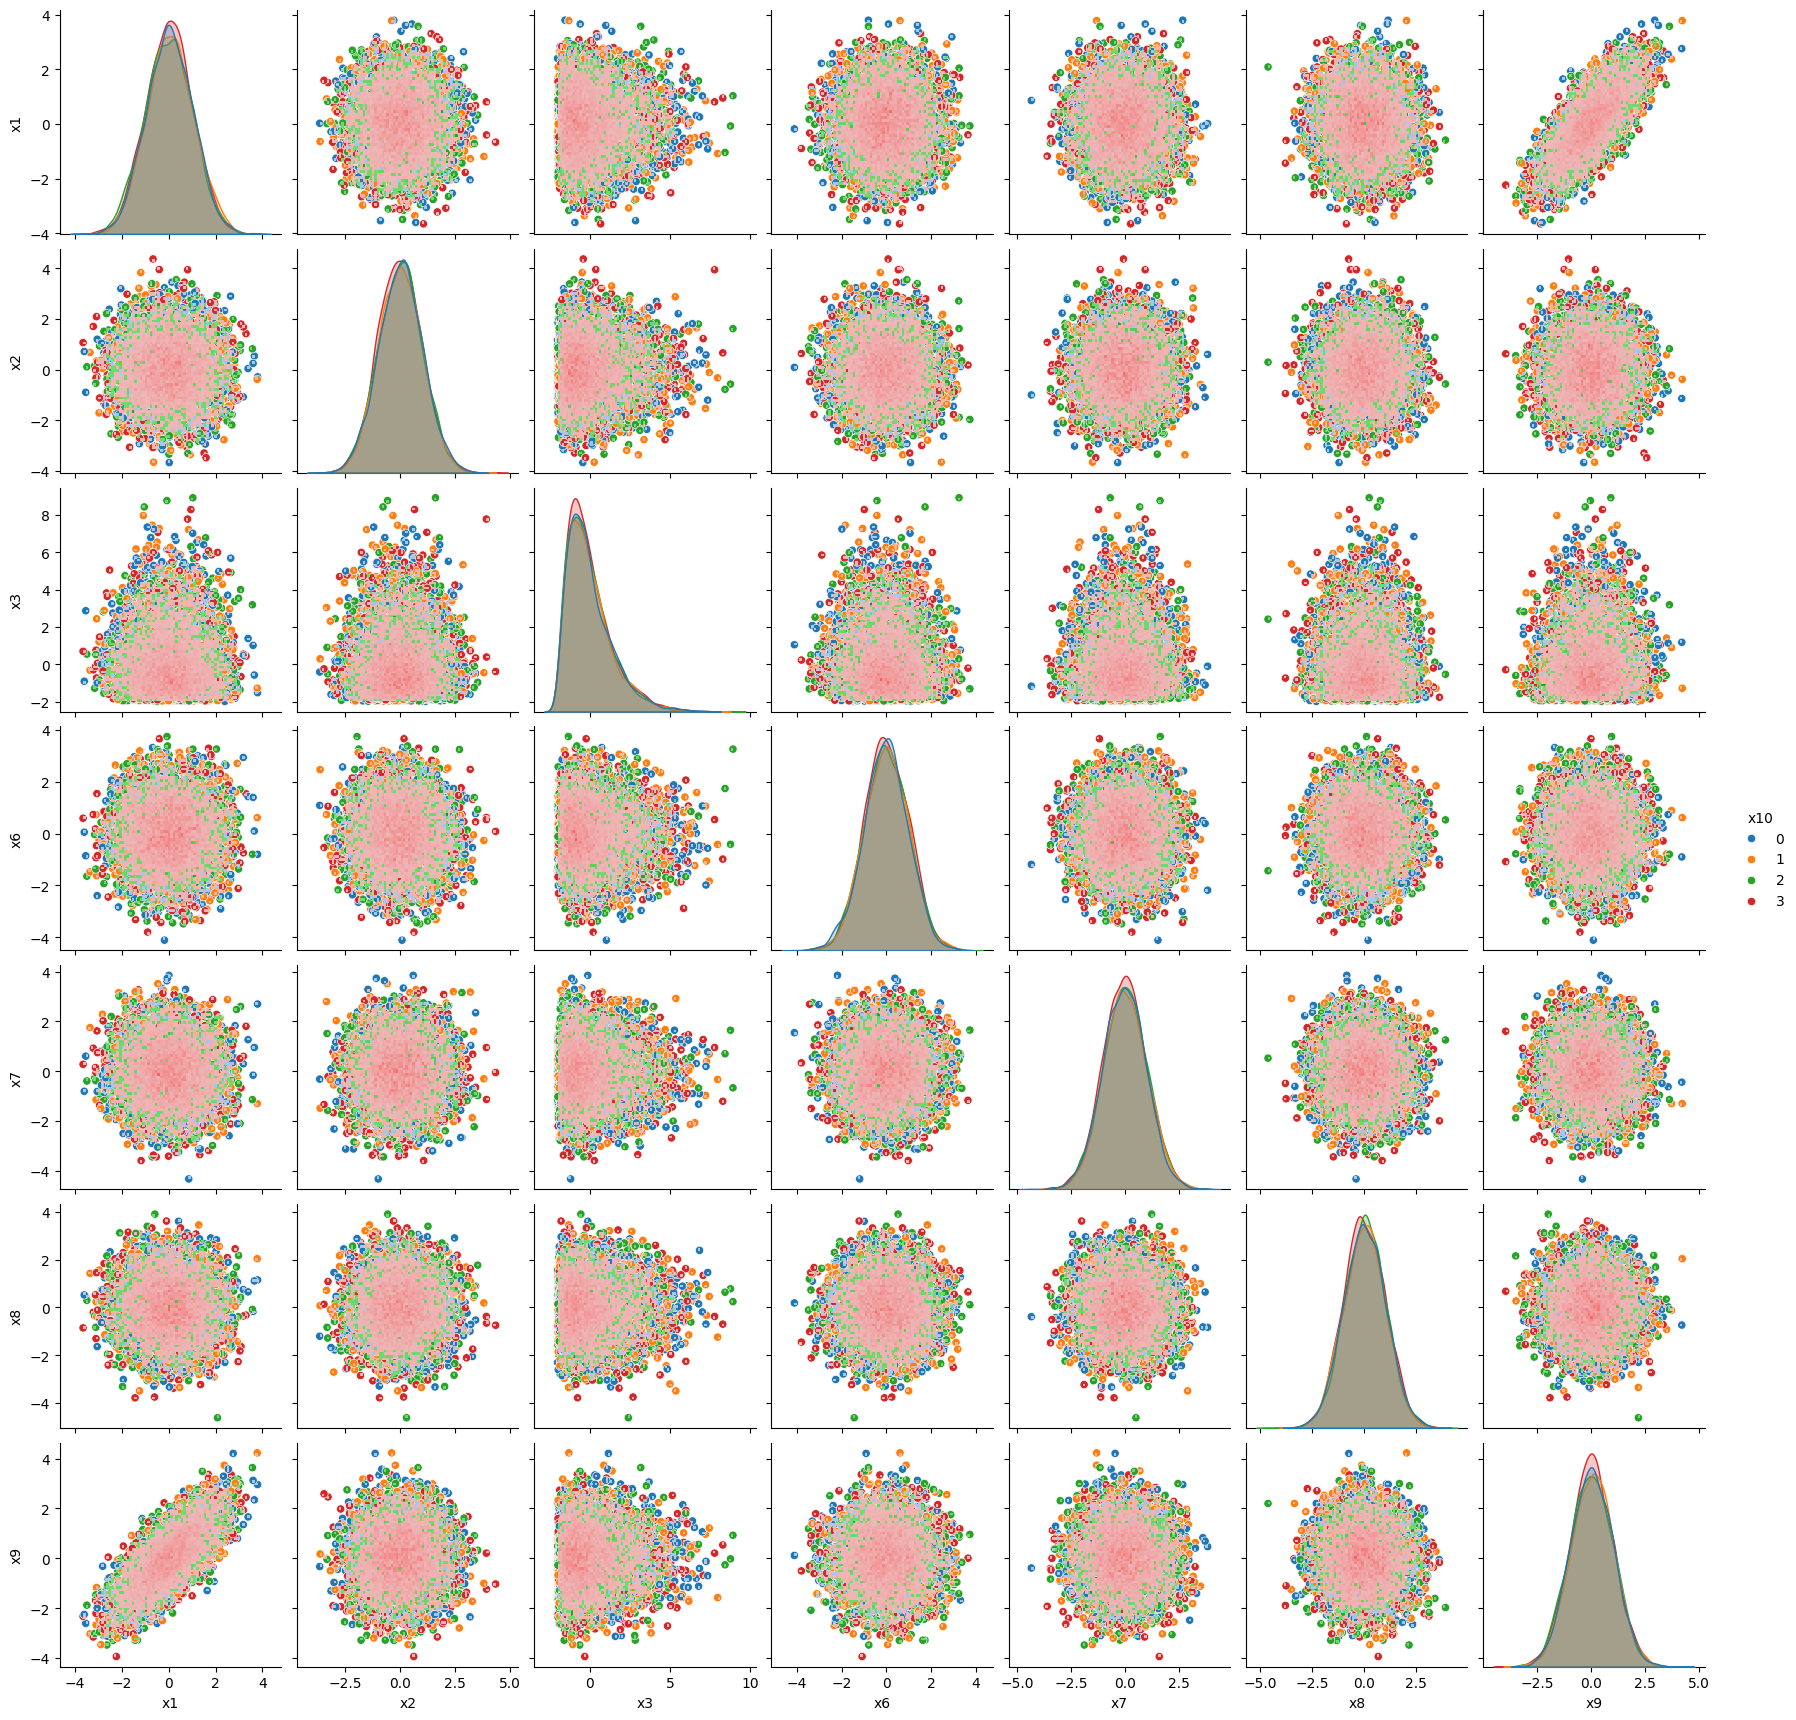

In [21]:
g = sns.pairplot(df_train, hue="x10")
g.map_offdiag(sns.histplot)
# g.map_lower(sns.kdeplot, fill=True)
display(g)

-> in all of the above pair plots:
- the diagonal distribution plots are invariant w.r.t. the categorical predictor
- the off-diagonal plots show no asymmetry in colors

**-> the categorical predictors seem to be independent of the numerical predictors**